# Clusteranalyse

## Präambel

Wir laden alle Pakete und Module, die wir im Folgenden benötigen.

In [1]:
# Paket für Daten
import kagglehub

# Visualisierung und Datentransformation
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Pakete für Clusteranalyse und Feature Selection
from sklearn import preprocessing
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans, SpectralClustering
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score
from sklearn.neighbors import NearestNeighbors, kneighbors_graph

# Funktionen für hierarchisches Clustering und Dendrogramme
from scipy.cluster.hierarchy import dendrogram, linkage

# Paket für Netzwerke
import networkx as nx

# Pakete für Landkarten
import geopandas
from pyproj import Transformer

## Daten

Whisky-Datensatz von https://www.kaggle.com/datasets/koki25ando/scotch-whisky-dataset

In [2]:
path = kagglehub.dataset_download("koki25ando/scotch-whisky-dataset") # Pfad zum heruntergeladenen Datensatz

# Lies die Daten ein
df = pd.read_csv(path + '/whisky.csv')

# Erster Blick auf den Datensatz
df

100%|██████████| 2.59k/2.59k [00:00<00:00, 1.43MB/s]

Extracting files...


,RowID,Distillery,Body,Sweetness,Smoky,Medicinal,Tobacco,Honey,Spicy,Winey,Nutty,Malty,Fruity,Floral,Postcode,Latitude,Longitude
0,1,Aberfeldy,2,2,2,0,0,2,1,2,2,2,2,2,\tPH15 2EB,286580,749680
1,2,Aberlour,3,3,1,0,0,4,3,2,2,3,3,2,\tAB38 9PJ,326340,842570
2,3,AnCnoc,1,3,2,0,0,2,0,0,2,2,3,2,\tAB5 5LI,352960,839320
3,4,Ardbeg,4,1,4,4,0,0,2,0,1,2,1,0,\tPA42 7EB,141560,646220
4,5,Ardmore,2,2,2,0,0,1,1,1,2,3,1,1,\tAB54 4NH,355350,829140
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
81,82,Tobermory,1,1,1,0,0,1,0,0,1,2,2,2,PA75 6NR,150450,755070
82,83,Tomatin,2,3,2,0,0,2,2,1,1,2,0,1,IV13 7YT,279120,829630
83,84,Tomintoul,0,3,1,0,0,2,2,1,1,2,1,2,AB37 9AQ,315100,825560
84,85,Tormore,2,2,1,0,0,1,0,1,2,1,0,0,PH26 3LR,315180,834960


Jede Zeile ist eine von 86 schottischen Destillerien. Für jede Destillerie gibt es zwölf Geschmacksmerkmale (`Body` bis `Floral`), die auf einer Skala von 0 (nicht vorhanden) bis 4 (sehr ausgeprägt) bewertet wurden. Dazu kommen die Postleitzahl (`Postcode`) und die Koordinaten der Destillerie (`Latitude`, `Longitude`).

Die Ausgaben oberhalb der Tabelle stammen von `kagglehub` und zeigen nur, dass der Datensatz heruntergeladen und entpackt wurde.

Der Datensatz enthält die Koordinaten der einzelnen Destillerien. Das könnte man sich auf einer Karte ansehen...

## Exkurs: Landkarten in Python

Das Paket `geopandas` bietet einen Rahmen für die Arbeit mit Geodaten. Das Modul `Transformer` aus dem Paket `pyproj` wird verwendet, um Koordinaten von einem Koordinatensystem in ein anderes umzurechnen.

Zunächst laden wir eine Karte des Vereinigten Königreichs.

In [3]:
# Karte von https://simplemaps.com/gis/country/gb, Koordinaten in Grad (EPSG:4326)
ctry = geopandas.read_file("gb.json")
ctry

,source,id,name,geometry
0,https://simplemaps.com,GBDRY,Derry,"POLYGON ((-7.41576 54.94437, -7.40866 54.95112..."
1,https://simplemaps.com,GBSTB,Strabane,"POLYGON ((-7.41576 54.94437, -7.41474 54.94373..."
2,https://simplemaps.com,GBFER,Fermanagh,"POLYGON ((-7.70795 54.60476, -7.69338 54.60075..."
3,https://simplemaps.com,GBDGN,Dungannon,"POLYGON ((-7.18947 54.33569, -7.18971 54.33604..."
4,https://simplemaps.com,GBARM,Armagh,"POLYGON ((-6.87001 54.326, -6.86743 54.3279, -..."
...,...,...,...,...
227,https://simplemaps.com,GBBIR,Birmingham,"POLYGON ((-1.85559 52.5755, -1.83169 52.58775,..."
228,https://simplemaps.com,GBSAW,Sandwell,"POLYGON ((-1.90281 52.54676, -1.91466 52.5278,..."
229,https://simplemaps.com,GBDUD,Dudley,"POLYGON ((-2.15387 52.42295, -2.15893 52.47742..."
230,https://simplemaps.com,GBWLL,Walsall,"POLYGON ((-2.05088 52.61743, -2.02589 52.61607..."


`ctry` ist ein `GeoDataFrame`: eine Tabelle wie in `pandas`, in der jede Zeile eine Region des Vereinigten Königreichs ist (insgesamt 232). Die Spalte `geometry` enthält die Umrisse der Regionen als Polygone in Längen- und Breitengraden.

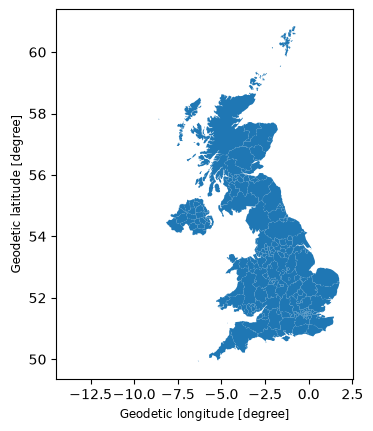

In [4]:
# Zeichne die Karte (alle Regionen des Vereinigten Königreichs)
ctry.plot()
plt.show()

Die Karte zeigt das gesamte Vereinigte Königreich inklusive Nordirland. Die Achsen sind in Grad angegeben: Längengrade auf der x-Achse, Breitengrade auf der y-Achse.

Dann legen wir unsere Daten über die Karte...

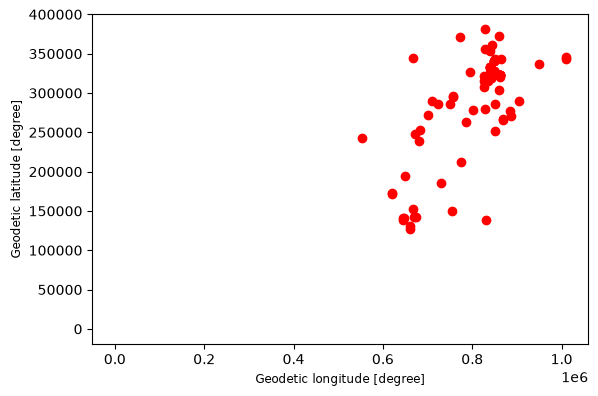

In [5]:
# Zeichne die Karte und lege die Destillerien als rote Punkte darüber
ctry.plot()
plt.scatter(x = df[['Longitude']], y = df[['Latitude']], marker='o', c = "red")
plt.show()

Die Punkte landen nicht auf der Karte: Die Achsen reichen jetzt bis 1.000.000 bzw. 400.000, und die Karte ist im Ursprung links unten nicht mehr zu erkennen. Der Grund ist, dass die Koordinaten im Whisky-Datensatz nicht in Grad, sondern im britischen Koordinatensystem *British National Grid* (EPSG:27700) in Metern angegeben sind. Außerdem sind die Spaltennamen irreführend: `Latitude` enthält den Ost-Wert (x) und `Longitude` den Nord-Wert (y). Deshalb übergeben wir im nächsten Schritt `Latitude` als erste Koordinate an den Transformer.

Wir müssen die Koordinatensysteme in ein einheitliches Format bringen. Dazu werden die Daten im Whisky-Datensatz transformiert:

In [6]:
# Stelle den Transformer ein: vom britischen Koordinatensystem (EPSG:27700) in Längen- und Breitengrade (EPSG:4326)
# always_xy=True: Reihenfolge immer (x, y), also Ost-Wert vor Nord-Wert bzw. Längengrad vor Breitengrad
transformer = Transformer.from_crs("EPSG:27700", "EPSG:4326", always_xy = True)

# Rechne alle Destillerien auf einmal um (Latitude enthält den Ost-Wert, Longitude den Nord-Wert)
lon, lat = transformer.transform(df['Latitude'], df['Longitude'])
coords_new = pd.DataFrame({'Longitude': lon, 'Latitude': lat})

# Zeige Ergebnis an
coords_new

,Longitude,Latitude
0,-3.850199,56.625191
1,-3.229644,57.467395
2,-2.785295,57.441751
3,-6.108503,55.640607
4,-2.743628,57.350557
...,...,...
81,-6.069530,56.620806
82,-4.010031,57.341101
83,-3.411083,57.312680
84,-3.412996,57.397107


Jetzt liegen die Koordinaten in Längen- und Breitengraden vor (EPSG:4326, dasselbe System wie die Karte). `transformer.transform` rechnet alle Destillerien auf einmal um: Wir übergeben die Ost-Werte (`Latitude`) und die Nord-Werte (`Longitude`) und erhalten Längen- und Breitengrade zurück.

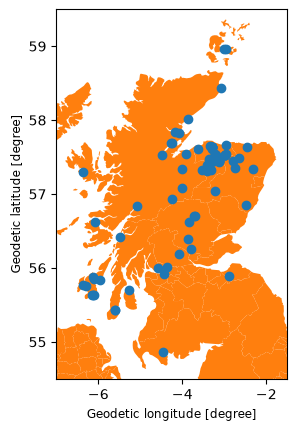

In [7]:
# Plotte Landkarte von UK
ctry.plot(color = "tab:orange")

# Füge Punkte hinzu
plt.scatter(x = coords_new[['Longitude']], y = coords_new[['Latitude']], marker='o', c = "tab:blue")

# Trimme die Grafik
plt.axis([-7, -1.5, 54.5, 59.5])

plt.show()

Nun passen Karte und Daten zusammen. Man erkennt bereits Regionen mit vielen Destillerien: eine starke Konzentration im Nordosten (Speyside), eine Gruppe auf der Insel Islay im Südwesten und einzelne Destillerien auf den Inseln und an der Küste.

## Datenaufbereitung für die Clusteranalyse

Für die Analyse bereiten wir den Datensatz auf.

In [8]:
# Lösche Spalten, die nicht benötigt werden
x = df.drop(columns = ['RowID', 'Distillery', 'Postcode', 'Longitude', 'Latitude', 'Fruity', 'Sweetness'])

# Zeige Ergebnis
x

,Body,Smoky,Medicinal,Tobacco,Honey,Spicy,Winey,Nutty,Malty,Floral
0,2,2,0,0,2,1,2,2,2,2
1,3,1,0,0,4,3,2,2,3,2
2,1,2,0,0,2,0,0,2,2,2
3,4,4,4,0,0,2,0,1,2,0
4,2,2,0,0,1,1,1,2,3,1
...,...,...,...,...,...,...,...,...,...,...
81,1,1,0,0,1,0,0,1,2,2
82,2,2,0,0,2,2,1,1,2,1
83,0,1,0,0,2,2,1,1,2,2
84,2,1,0,0,1,0,1,2,1,0


Für die Clusteranalyse nach Geschmack behalten wir nur die Geschmacksmerkmale. ID, Name, Postleitzahl und Koordinaten werden entfernt, ebenso die Merkmale `Fruity` und `Sweetness`. Es bleiben 86 Destillerien mit 10 Merkmalen.

### Normalisierung

In [9]:
# Skaliere jedes Merkmal auf den Bereich [0, 1]: (x - min) / (max - min)
min_max_scaler = preprocessing.MinMaxScaler()
x_scaled = min_max_scaler.fit_transform(x)

# fit_transform liefert ein NumPy-Array, daher wandeln wir es wieder in einen Data Frame um
x_scaled = pd.DataFrame(x_scaled)
x_scaled.columns = x.columns

x_scaled

,Body,Smoky,Medicinal,Tobacco,Honey,Spicy,Winey,Nutty,Malty,Floral
0,0.50,0.50,0.0,0.0,0.50,0.333333,0.50,0.50,0.666667,0.50
1,0.75,0.25,0.0,0.0,1.00,1.000000,0.50,0.50,1.000000,0.50
2,0.25,0.50,0.0,0.0,0.50,0.000000,0.00,0.50,0.666667,0.50
3,1.00,1.00,1.0,0.0,0.00,0.666667,0.00,0.25,0.666667,0.00
4,0.50,0.50,0.0,0.0,0.25,0.333333,0.25,0.50,1.000000,0.25
...,...,...,...,...,...,...,...,...,...,...
81,0.25,0.25,0.0,0.0,0.25,0.000000,0.00,0.25,0.666667,0.50
82,0.50,0.50,0.0,0.0,0.50,0.666667,0.25,0.25,0.666667,0.25
83,0.00,0.25,0.0,0.0,0.50,0.666667,0.25,0.25,0.666667,0.50
84,0.50,0.25,0.0,0.0,0.25,0.000000,0.25,0.50,0.333333,0.00


Nach der Min-Max-Normalisierung liegen alle Merkmale zwischen 0 und 1. Das ist wichtig, weil k-means mit Distanzen arbeitet: Ohne Normalisierung hätten Merkmale mit größerer Spannweite automatisch mehr Gewicht. Hier sind die meisten Merkmale schon auf derselben Skala von 0 bis 4. `Tobacco` hat aber nur die Werte 0 und 1 und bekommt durch die Skalierung viermal so viel Gewicht wie vorher. Das prägt die Ergebnisse unten: Die wenigen Whiskys mit Tabaknote bilden fast immer ein eigenes Cluster. Ein Wert von 0,5 bei `Body` bedeutet hier, dass die Destillerie genau in der Mitte zwischen dem kleinsten und dem größten beobachteten Wert liegt.

In [10]:
# Korrelationsmatrix der (skalierten) Geschmacksmerkmale
x_scaled.corr()

,Body,Smoky,Medicinal,Tobacco,Honey,Spicy,Winey,Nutty,Malty,Floral
Body,1.000000,0.524032,0.354050,0.168718,0.082031,0.188500,0.408576,0.126323,-0.116859,-0.461203
Smoky,0.524032,1.000000,0.686071,0.365501,-0.195318,0.231745,-0.028190,-0.023132,-0.192875,-0.431663
Medicinal,0.354050,0.686071,1.000000,0.425106,-0.396629,0.044903,-0.202651,-0.113671,-0.258959,-0.511323
Tobacco,0.168718,0.365501,0.425106,1.000000,-0.275490,0.054068,0.009097,-0.117717,-0.059347,-0.212375
Honey,0.082031,-0.195318,-0.396629,-0.275490,1.000000,0.139563,0.362021,0.188492,0.310184,0.183029
Spicy,0.188500,0.231745,0.044903,0.054068,0.139563,1.000000,0.092704,-0.042856,0.036303,0.034663
Winey,0.408576,-0.028190,-0.202651,0.009097,0.362021,0.092704,1.000000,0.198467,0.112368,-0.126932
Nutty,0.126323,-0.023132,-0.113671,-0.117717,0.188492,-0.042856,0.198467,1.000000,0.066157,0.018302
Malty,-0.116859,-0.192875,-0.258959,-0.059347,0.310184,0.036303,0.112368,0.066157,1.000000,0.106309
Floral,-0.461203,-0.431663,-0.511323,-0.212375,0.183029,0.034663,-0.126932,0.018302,0.106309,1.000000


Die Korrelationsmatrix zeigt, welche Geschmacksmerkmale gemeinsam auftreten:

* `Smoky` und `Medicinal` hängen stark positiv zusammen (0,69), ebenso `Body` und `Smoky` (0,52). Rauchige Whiskys sind also oft auch medizinisch und vollmundig.
* `Floral` hängt negativ mit `Medicinal` (−0,51), `Body` (−0,46) und `Smoky` (−0,43) zusammen. Blumige Whiskys sind eher leicht und nicht rauchig.

Diese Zusammenhänge deuten darauf hin, dass es unterschiedliche Geschmacksprofile gibt, die eine Clusteranalyse finden könnte.

## Partitionierende Verfahren

Partitionierende Verfahren teilen die Daten in eine vorgegebene Anzahl $k$ von Clustern auf. Jede Beobachtung gehört zu genau einem Cluster, und jedes Cluster wird durch ein repräsentatives Objekt beschrieben, bei k-means durch den Mittelwert seiner Beobachtungen (das *Zentrum*). Als Beispiel verwenden wir das bekannteste Verfahren, k-means.

### k-means

Wir verwenden Funktionen des `scikit-learn` Pakets. Daher ist der Ablauf ähnlich wie im Skript zur Klassifikation.

In [11]:
# Erstelle ein 'leeres' Modell
# mit der Annahme, dass 3 Cluster in den Daten zu finden sind.
# random_state=0 legt die zufälligen Startwerte fest, damit das Ergebnis reproduzierbar ist
kmeans = KMeans(n_clusters = 3, n_init = 'auto', random_state = 0)

# Trainiere das Modell
kmeans.fit(x_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary `.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


Die Ausgabe zeigt nur das trainierte Modell mit seinen Parametern. Die eigentlichen Ergebnisse fragen wir in den nächsten Zellen ab.

In [12]:
# Zeige die 'Koordinaten' der repräsentativen Punkte an
kmeans.cluster_centers_

array([[ 3.65384615e-01,  2.88461538e-01,  9.61538462e-02,
        -1.11022302e-16,  2.37179487e-01,  3.41880342e-01,
         1.02564103e-01,  3.20512821e-01,  5.47008547e-01,
         4.93589744e-01],
       [ 6.28571429e-01,  4.00000000e-01,  5.71428571e-02,
        -9.71445147e-17,  4.50000000e-01,  5.61904762e-01,
         4.14285714e-01,  4.42857143e-01,  6.66666667e-01,
         4.07142857e-01],
       [ 6.87500000e-01,  6.45833333e-01,  5.00000000e-01,
         8.33333333e-01,  1.45833333e-01,  5.55555556e-01,
         2.08333333e-01,  2.91666667e-01,  5.83333333e-01,
         2.50000000e-01]])

Jede Zeile ist das Zentrum eines Clusters, jede Spalte ein Merkmal in der Reihenfolge von `x_scaled` (`Body`, `Smoky`, `Medicinal`, `Tobacco`, `Honey`, `Spicy`, `Winey`, `Nutty`, `Malty`, `Floral`). Werte wie `-1.1e-16` sind Rundungsfehler und bedeuten 0.

Die Zentren lassen sich so lesen:

* **Cluster 0**: insgesamt niedrige Werte, aber eher blumig (`Floral` 0,49), also leichte, milde Whiskys.
* **Cluster 1**: vollmundig (`Body` 0,63), würzig (`Spicy` 0,56), malzig (`Malty` 0,67) mit etwas Honig (0,45), also eher kräftige, runde Whiskys.
* **Cluster 2**: rauchig (`Smoky` 0,65), medizinisch (`Medicinal` 0,50) und mit Tabaknote (`Tobacco` 0,83): 10 der 12 Destillerien in diesem Cluster haben eine Tabaknote.

k-means startet mit zufälligen Zentren. Ohne `random_state` können bei einem neuen Durchlauf die Nummern der Cluster vertauscht sein oder die Cluster etwas anders ausfallen.

In [13]:
# Weise jede Destillerie dem nächstgelegenen Clusterzentrum zu
labels_kmeans = kmeans.predict(x_scaled)
labels_kmeans

array([1, 1, 0, 2, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 2,
       0, 2, 2, 0, 1, 1, 0, 1, 0, 1, 2, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1,
       1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 2, 2, 0, 0, 1, 1, 0, 0, 1,
       0, 2, 2, 2, 1, 1, 0, 0, 1, 1, 0, 2, 0, 0, 0, 0, 1, 0, 0, 2],
      dtype=int32)

Für jede der 86 Destillerien (in der Reihenfolge des Datensatzes) gibt die Ausgabe die Nummer des Clusters an: 39 Destillerien sind in Cluster 0, 35 in Cluster 1 und 12 in Cluster 2. Im Cluster 2 (rauchig bzw. mit Tabaknote) finden sich unter anderem Ardbeg, Lagavulin, Laphroaig und Caol Ila von der Insel Islay und Talisker von der Isle of Skye, aber auch kaum rauchige Whiskys mit Tabaknote wie Tullibardine. Wir speichern die Zuordnung in `labels_kmeans`, um sie später mit den anderen Verfahren zu vergleichen.

## Hierarchische Verfahren

Hierarchische Verfahren ordnen die Beobachtungen in einen Baum von Clustern ein. *Agglomerative* Verfahren arbeiten von unten nach oben (bottom-up): Am Anfang ist jede Beobachtung ein eigenes Cluster, und in jedem Schritt werden die beiden ähnlichsten Cluster zusammengelegt, bis nur noch eines übrig ist. *Divisive* Verfahren gehen umgekehrt vor (top-down).

Wie „ähnlich“ zwei Cluster sind, legt die *Linkage* fest. Wir verwenden das **Ward-Verfahren**: Es legt jeweils die beiden Cluster zusammen, bei denen die Summe der quadrierten Abstände zu den Clusterzentren am wenigsten steigt. Das ist dasselbe Kriterium wie bei k-means, nur schrittweise angewendet. Der Baum lässt sich als *Dendrogramm* darstellen.

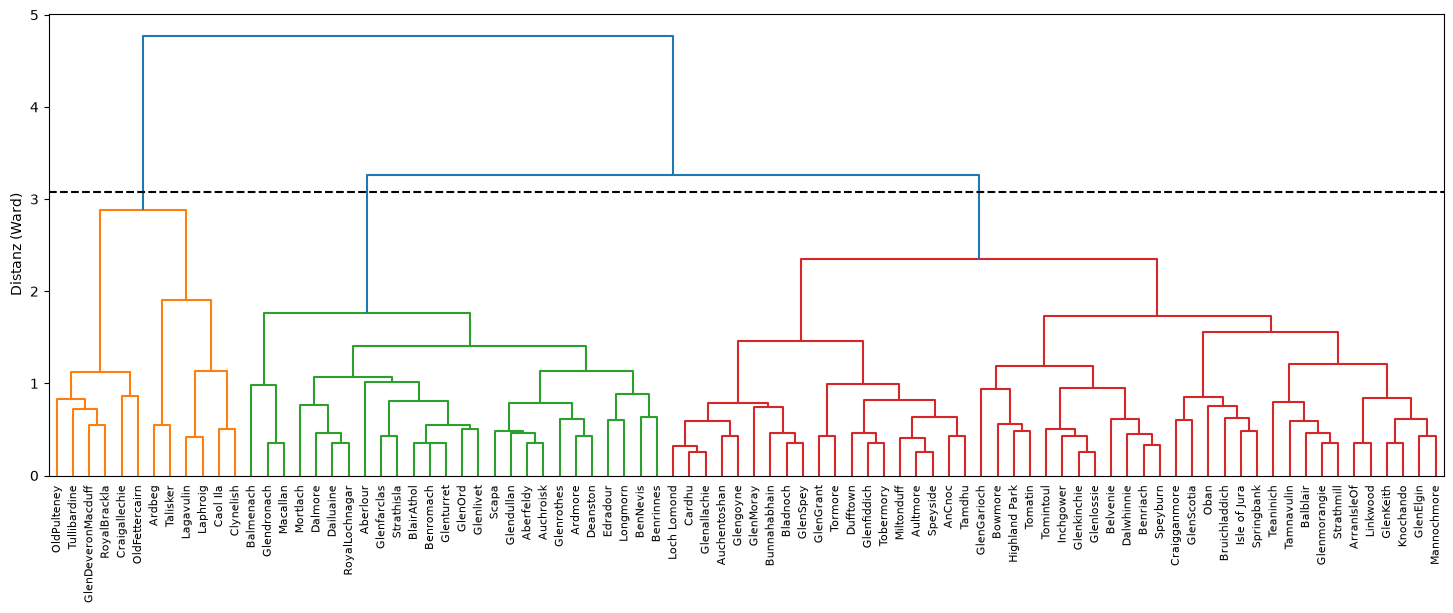

In [14]:
# Berechne die gesamte Hierarchie mit dem Ward-Verfahren
Z = linkage(x_scaled, method = 'ward')

# Jede Zeile von Z ist ein Schritt: die beiden zusammengelegten Cluster, ihre Distanz und die Größe des neuen Clusters
# Die Höhe, bei der genau 3 Cluster entstehen, liegt zwischen den letzten beiden Schritten
cut_height = (Z[-3, 2] + Z[-2, 2]) / 2

# Zeichne das Dendrogramm mit den Namen der Destillerien
plt.figure(figsize = (18, 6))
dendrogram(Z, labels = df['Distillery'].tolist(), leaf_font_size = 8, color_threshold = cut_height)
plt.axhline(y = cut_height, color = 'black', linestyle = '--') # Schnitt für 3 Cluster
plt.ylabel('Distanz (Ward)')
plt.show()

Jede Destillerie ist ein Blatt am unteren Rand. Je weiter oben zwei Äste zusammenlaufen, desto unähnlicher sind die zusammengelegten Cluster. Schneidet man den Baum an der gestrichelten Linie, entstehen 3 Cluster (die Farben):

* **Orange (12 Destillerien):** die rauchigen Whiskys und die Whiskys mit Tabaknote. Innerhalb dieses Astes trennen sich die torfigen Whiskys (Ardbeg, Lagavulin, Laphroaig, Caol Ila, Talisker und Clynelish) von einer Gruppe kaum rauchiger Whiskys mit Tabaknote (Craigallechie, Glen Deveron, Old Fettercairn, Old Pulteney, Royal Brackla und Tullibardine).
* **Grün (26) und Rot (48):** die übrigen Whiskys. Sie laufen erst bei einer Distanz von rund 3,3 zusammen, mit dem orangen Ast sogar erst bei 4,8.

Das Dendrogramm zeigt die ganze Hierarchie auf einmal: Ein Schnitt weiter unten ergibt mehr, kleinere Cluster, ein Schnitt weiter oben weniger. Der Schnitt für 3 Cluster liegt allerdings nah an dem für 4 Cluster (bei 2,9 teilt sich der orange Ast). Die Wahl von 3 Clustern ist also nicht eindeutig.

In [15]:
# Erstelle ein 'leeres' Modell mit 3 Clustern und dem Ward-Verfahren
agglo = AgglomerativeClustering(n_clusters = 3, linkage = 'ward')

# Trainiere das Modell und weise jeder Destillerie ein Cluster zu
labels_agglo = agglo.fit_predict(x_scaled)

# Anzahl der Destillerien je Cluster
np.bincount(labels_agglo)

array([12, 48, 26])

`AgglomerativeClustering` schneidet den Baum an der Stelle, an der 3 Cluster entstehen, und liefert dieselbe Einteilung wie die gestrichelte Linie im Dendrogramm. Anders als k-means hat das Verfahren keine Methode `predict`, weil das Verfahren keine Zentren schätzt, mit denen neue Beobachtungen zugeordnet werden könnten. Anders als k-means verwendet das Verfahren keine Zufallszahlen, das Ergebnis ist also bei jedem Durchlauf gleich.

In [16]:
# Durchschnittliches Geschmacksprofil je Cluster (Originalskala 0 bis 4)
x.groupby(labels_agglo).mean().round(2)

,Body,Smoky,Medicinal,Tobacco,Honey,Spicy,Winey,Nutty,Malty,Floral
0,2.75,2.58,2.00,0.83,0.58,1.67,0.83,1.17,1.75,1.00
1,1.56,1.31,0.44,0.00,1.10,1.21,0.52,1.27,1.62,1.90
2,2.69,1.46,0.08,0.00,1.81,1.58,1.88,1.96,2.15,1.65


Die Cluster lassen sich über ihr durchschnittliches Geschmacksprofil interpretieren:

* **Cluster 0** (12 Destillerien, orange im Dendrogramm): rauchig (`Smoky` 2,58) und medizinisch (`Medicinal` 2,00), 10 der 12 mit Tabaknote.
* **Cluster 1** (48, rot): leicht und blumig (`Body` 1,56, `Floral` 1,90).
* **Cluster 2** (26, grün): vollmundig (`Body` 2,69) mit Noten von Wein, Honig, Nüssen und Malz. Hier liegen unter anderem Macallan, Glendronach und Dalmore, die für ihre Reifung in Sherryfässern bekannt sind.

## DBSCAN

k-means und hierarchisches Clustering ordnen *jede* Beobachtung einem Cluster zu, und bei k-means muss die Anzahl der Cluster vorab festgelegt werden. **DBSCAN** (*Density-Based Spatial Clustering of Applications with Noise*) geht anders vor: Ein Cluster ist ein Bereich, in dem die Beobachtungen dicht beieinander liegen. Der Algorithmus braucht dafür zwei Parameter:

* `eps`: der Radius, innerhalb dessen zwei Beobachtungen als Nachbarn gelten,
* `min_samples`: die Mindestanzahl an Beobachtungen (inklusive der Beobachtung selbst) innerhalb von `eps`, damit eine Beobachtung als *Kernpunkt* gilt.

Kernpunkte, die direkt oder über eine Kette weiterer Kernpunkte jeweils höchstens `eps` voneinander entfernt sind, bilden gemeinsam ein Cluster. Beobachtungen in der Nähe eines Kernpunkts, die selbst kein Kernpunkt sind, werden als *Randpunkte* dem Cluster zugeordnet. Alle übrigen Beobachtungen gelten als *Rauschen* und erhalten das Label `-1`. Die Anzahl der Cluster ergibt sich also aus den Daten, und Cluster können beliebige Formen annehmen.

Wir wenden DBSCAN auf die Standorte der Destillerien an. Die ursprünglichen Koordinaten im Datensatz sind im britischen Koordinatensystem (EPSG:27700) in Metern angegeben. Rechnen wir sie in Kilometer um, lässt sich `eps` direkt als Entfernung interpretieren. Deshalb verzichten wir hier auf die Normalisierung.

In [17]:
# Koordinaten in Kilometern (EPSG:27700 ist in Metern angegeben)
x_geo = df[['Latitude', 'Longitude']] / 1000

x_geo.head()

,Latitude,Longitude
0,286.58,749.68
1,326.34,842.57
2,352.96,839.32
3,141.56,646.22
4,355.35,829.14


### Wahl von `eps`

Eine gängige Heuristik für die Wahl von `eps` ist der *k-Distanz-Plot*: Für jede Beobachtung berechnen wir die Entfernung zu ihrem `min_samples`-nächsten Nachbarn (die Beobachtung selbst zählt mit) und sortieren diese Entfernungen der Größe nach. Ein geeigneter Wert für `eps` liegt dort, wo die Kurve deutlich ansteigt.

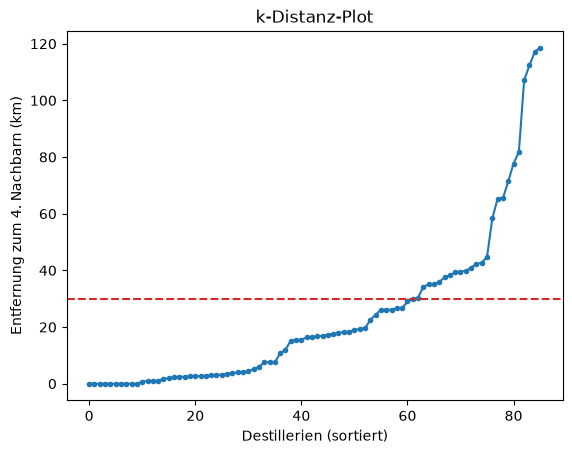

In [18]:
min_samples = 4

# Berechne für jede Beobachtung die Entfernungen zu den nächsten Nachbarn
nn = NearestNeighbors(n_neighbors = min_samples)
nn.fit(x_geo)
distances, _ = nn.kneighbors(x_geo)

# Sortiere die Entfernung zum min_samples-nächsten Nachbarn
k_dist = np.sort(distances[:, min_samples - 1])

plt.plot(k_dist, marker = '.')
plt.axhline(30, color = "tab:red", linestyle = "--")
plt.title('k-Distanz-Plot')
plt.xlabel('Destillerien (sortiert)')
plt.ylabel('Entfernung zum ' + str(min_samples) + '. Nachbarn (km)')
plt.show()

Bis etwa 30 km steigt die Kurve flach an, danach wird sie steiler, und ab etwa 45 km folgen nur noch wenige, abgelegene Destillerien. Wir wählen `eps = 30` (km) und nehmen in Kauf, dass etwas mehr Destillerien als Rauschen gelten.

### Training

In [19]:
# Erstelle ein 'leeres' Modell
dbscan = DBSCAN(eps = 30, min_samples = min_samples)

# Trainiere das Modell und weise jeder Destillerie ein Label zu
pred_dbscan = dbscan.fit_predict(x_geo)

# Anzahl der Destillerien je Cluster (-1 = Rauschen)
pd.Series(pred_dbscan).value_counts().sort_index()

-1    15
 0     9
 1    54
 2     8
Name: count, dtype: int64

Anders als bei k-means gibt es keine Methode `predict`, weil DBSCAN keine Clusterzentren schätzt, mit denen neue Beobachtungen zugeordnet werden könnten. Deshalb verwenden wir `fit_predict`.

### Visualisierung

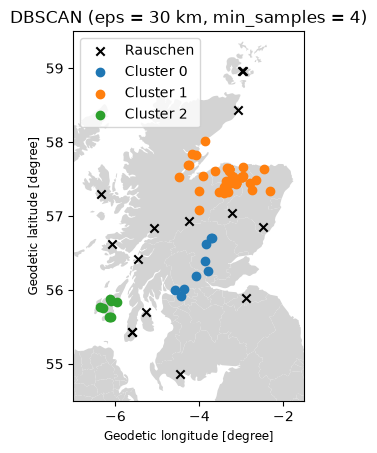

In [20]:
# Plotte Landkarte von UK
ctry.plot(color = "lightgrey")

# Rauschen (Label -1) in Schwarz
noise = pred_dbscan == -1
plt.scatter(x = coords_new.loc[noise, 'Longitude'], y = coords_new.loc[noise, 'Latitude'],
            marker = 'x', c = "black", label = "Rauschen")

# Cluster in Farbe
for label in sorted(set(pred_dbscan) - {-1}):
    sel = pred_dbscan == label
    plt.scatter(x = coords_new.loc[sel, 'Longitude'], y = coords_new.loc[sel, 'Latitude'],
                marker = 'o', label = "Cluster " + str(label))

# Trimme die Grafik
plt.axis([-7, -1.5, 54.5, 59.5])
plt.legend(loc = "upper left")
plt.title("DBSCAN (eps = 30 km, min_samples = " + str(min_samples) + ")")
plt.show()

DBSCAN findet die dichten Regionen mit vielen Destillerien, darunter die Speyside mit den umliegenden Highlands als größtes Cluster, eine Gruppe in Zentralschottland und die Insel Islay, ohne dass wir die Anzahl der Cluster vorgeben mussten. Abgelegene Destillerien, etwa auf den Orkney-Inseln oder an der Westküste, werden nicht in ein Cluster gezwungen, sondern als Rauschen markiert. Das Ergebnis hängt allerdings stark von `eps` und `min_samples` ab: Ein kleineres `eps` zerlegt die Daten in mehr und kleinere Cluster mit mehr Rauschen, ein größeres `eps` verschmilzt benachbarte Regionen. Probiere verschiedene Werte aus!

## Evaluation

Die Clusteranalyse ist ein Verfahren des unüberwachten Lernens: Anders als bei der Klassifikation gibt es keine richtigen Antworten, mit denen wir die Ergebnisse vergleichen könnten. Han et al. (2023) unterscheiden drei Fragen:

1. **Clustering-Tendenz:** Haben die Daten überhaupt eine Clusterstruktur? Jedes Verfahren findet Cluster, auch in rein zufälligen Daten.
2. **Anzahl der Cluster:** Wie viele Cluster sind sinnvoll?
3. **Qualität:** Wie gut ist ein Clustering? *Extrinsische* Maße vergleichen es mit einer bekannten Einteilung (*Ground Truth*), *intrinsische* Maße beurteilen es allein anhand der Daten, z. B. wie kompakt und wie klar getrennt die Cluster sind.

### Clustering-Tendenz: Hopkins-Statistik

Die Hopkins-Statistik vergleicht die Daten mit gleichverteilten Zufallspunkten:

* Für $n$ Zufallspunkte, gleichverteilt im Wertebereich der Daten, messen wir die Distanz $x_i$ zur nächsten Beobachtung.
* Für jede Beobachtung messen wir die Distanz $y_i$ zur nächsten *anderen* Beobachtung.
* $H = \sum y_i / (\sum x_i + \sum y_i)$.

Sind die Daten gleichverteilt, sind beide Distanzen ähnlich groß und $H$ liegt nahe 0,5. Bilden die Daten dichte Gruppen, liegen die Beobachtungen nahe beieinander, die Zufallspunkte aber oft in leeren Bereichen. Dann ist $\sum y_i$ klein und $H$ nahe 0. (Manche Quellen definieren die Statistik umgekehrt als $1 - H$, dann bedeuten Werte nahe 1 eine Clusterstruktur.)

In [21]:
def hopkins(X, seed = 0):
    rng = np.random.default_rng(seed)
    nn = NearestNeighbors(n_neighbors = 2).fit(X)

    # Zufallspunkte, gleichverteilt im Wertebereich der Daten, und ihre Distanz zur nächsten Beobachtung
    uniform_points = rng.uniform(X.min(axis = 0), X.max(axis = 0), size = X.shape)
    dist_uniform = nn.kneighbors(uniform_points, n_neighbors = 1)[0][:, 0]

    # Distanz jeder Beobachtung zur nächsten anderen Beobachtung (der nächste Nachbar ist sie selbst)
    dist_data = nn.kneighbors(X, n_neighbors = 2)[0][:, 1]

    return dist_data.sum() / (dist_uniform.sum() + dist_data.sum())

print(f"Geschmack (x_scaled): H = {hopkins(x_scaled.to_numpy()):.2f}")
print(f"Standort (x_geo):     H = {hopkins(x_geo.to_numpy()):.2f}")

Geschmack (x_scaled): H = 0.33
Standort (x_geo):     H = 0.20


Für den Standort ist $H$ = 0,20, für den Geschmack 0,33. Beide Werte liegen unter 0,5, beide Datensätze haben also eine gewisse Clusterstruktur. Beim Standort ist sie deutlicher, mit vielen Destillerien in der Speyside und einer Gruppe auf Islay. Beim Geschmack ist sie schwächer: Die Whiskys bilden eher ein Kontinuum mit einigen auffälligen Gruppen. Beim Standort drückt zusätzlich nach unten, dass einige Destillerien im Datensatz exakt dieselben Koordinaten haben (Abstand 0). Das Ergebnis hängt außerdem von den Zufallspunkten ab, mit einem anderen `seed` ändern sich die Werte leicht.

### Anzahl der Cluster

Eine beliebte Methode für die Wahl der Anzahl der Cluster ist die *Elbow-Methode*. Dafür wird k-means für eine Reihe von Kandidaten ausgeführt und jeweils die *Inertia* berechnet, die Summe der quadrierten Distanzen zum eigenen Zentrum. Mit mehr Clustern sinkt sie (bei der jeweils besten Lösung) immer. Damit k-means nicht in einer schlechten Lösung hängen bleibt, starten wir es mit 10 verschiedenen Startwerten (`n_init = 10`) und behalten das beste Ergebnis. Gesucht ist der Punkt, ab dem zusätzliche Cluster kaum noch etwas bringen (der „Ellbogen“).

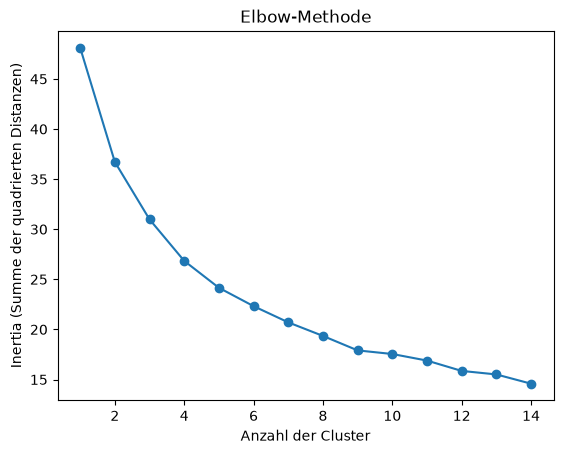

In [22]:
# Inertia für 1 bis 14 Cluster
inertias = []
for k in range(1, 15):
    # Trainiere k-means mit k Clustern und 10 verschiedenen Startwerten
    kmeans = KMeans(n_clusters = k, n_init = 10, random_state = 0)
    kmeans.fit(x_scaled)
    inertias.append(kmeans.inertia_)

# Stelle das Resultat grafisch dar
plt.plot(range(1, 15), inertias, marker = 'o')
plt.title('Elbow-Methode')
plt.xlabel('Anzahl der Cluster')
plt.ylabel('Inertia (Summe der quadrierten Distanzen)')
plt.show()

Die Inertia sinkt von 1 auf 2 und 3 Cluster deutlich (von 48 auf 37 und 31), danach immer flacher und ohne klaren Knick. Einen eindeutigen Ellbogen gibt es nicht, am ehesten liegt er bei 3 Clustern. Das passt zur Hopkins-Statistik: Beim Geschmack ist die Clusterstruktur schwach. Die Elbow-Methode ist daher eher eine Orientierungshilfe als eine exakte Regel.

Ein zweites Kriterium ist der **Silhouette-Koeffizient**. Für jede Beobachtung ist $a$ die mittlere Distanz zu den anderen Beobachtungen im eigenen Cluster und $b$ die mittlere Distanz zu den Beobachtungen im nächstgelegenen anderen Cluster. Der Koeffizient $s = (b - a) / \max(a, b)$ liegt zwischen −1 und 1. Werte nahe 1 bedeuten, dass die Beobachtung gut in ihr Cluster passt, Werte nahe 0, dass sie zwischen zwei Clustern liegt. Der Durchschnitt über alle Beobachtungen ist ein intrinsisches Maß für die Qualität eines Clusterings.

Wir berechnen ihn für k-means und das agglomerative Verfahren mit 2 bis 6 Clustern.

In [23]:
scores = []
for k in range(2, 7):
    # Cluster-Zuordnungen beider Verfahren mit k Clustern
    labels_k = {
        'k-means': KMeans(n_clusters = k, n_init = 'auto', random_state = 0).fit_predict(x_scaled),
        'Agglomerativ (Ward)': AgglomerativeClustering(n_clusters = k, linkage = 'ward').fit_predict(x_scaled),
    }
    for method, labels in labels_k.items():
        scores.append({'Cluster': k, 'Verfahren': method, 'Silhouette': silhouette_score(x_scaled, labels)})

# Eine Zeile je Anzahl an Clustern, eine Spalte je Verfahren
scores = pd.DataFrame(scores).pivot(index = 'Cluster', columns = 'Verfahren', values = 'Silhouette')
scores.round(3)

Verfahren,Agglomerativ (Ward),k-means
Cluster,,
2,0.388,0.388
3,0.167,0.173
4,0.187,0.139
5,0.153,0.140
6,0.165,0.144


Alle Werte sind niedrig. Am höchsten ist der Silhouette-Koeffizient bei 2 Clustern (0,39 für k-means und das agglomerative Verfahren). Beim agglomerativen Verfahren ist das die oberste Teilung im Dendrogramm: die rauchigen Whiskys gegen den Rest. Ab 3 Clustern liegen alle Werte zwischen 0,14 und 0,19, viele Destillerien liegen also nahe an der Grenze zwischen zwei Clustern.

### Silhouette-Analyse im Detail: regionale Cluster

Die Silhouette-Werte der einzelnen Beobachtungen zeigen auch, *wo* ein Clustering gut oder schlecht passt. Als Beispiel clustern wir die Destillerien mit k-means nach ihrem Standort, denn dort ist die Clusterstruktur laut Hopkins-Statistik deutlicher als beim Geschmack. Wie bei DBSCAN verwenden wir die Koordinaten in Kilometern (`x_geo`), damit die Distanzen echten Entfernungen entsprechen.

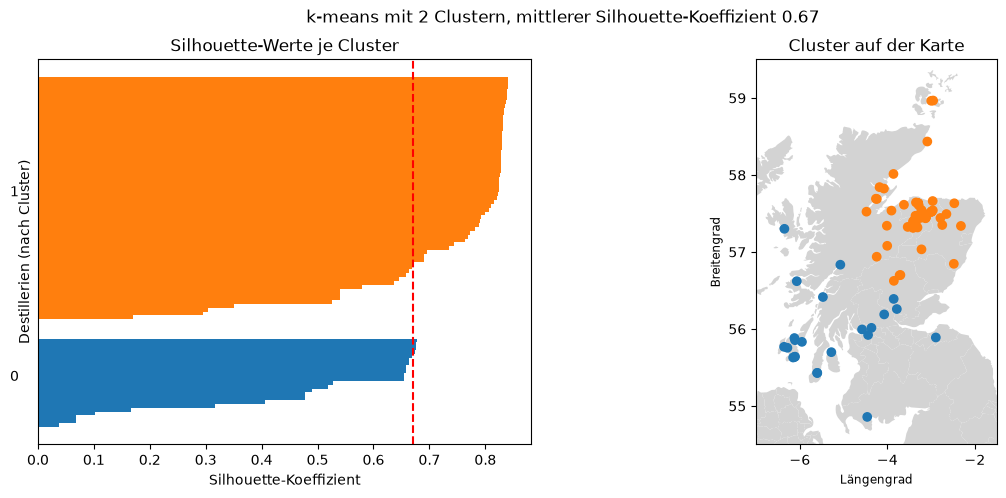

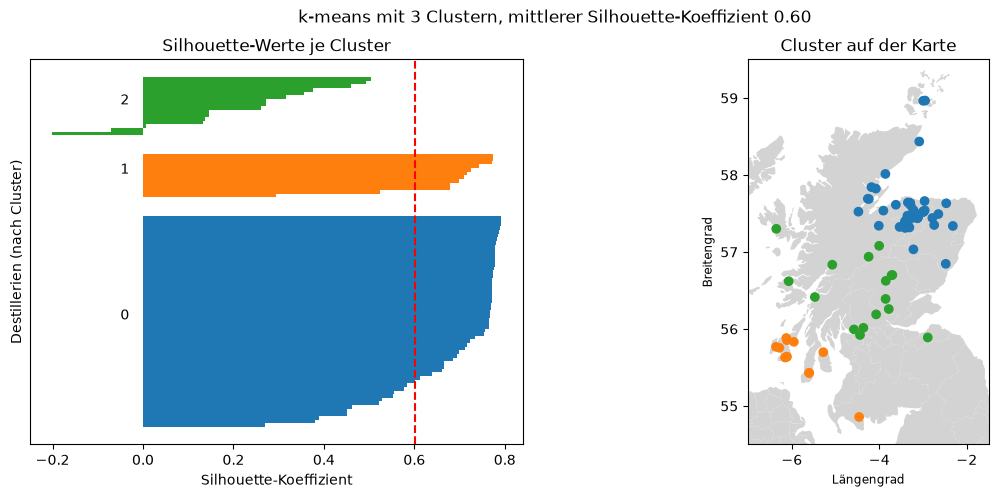

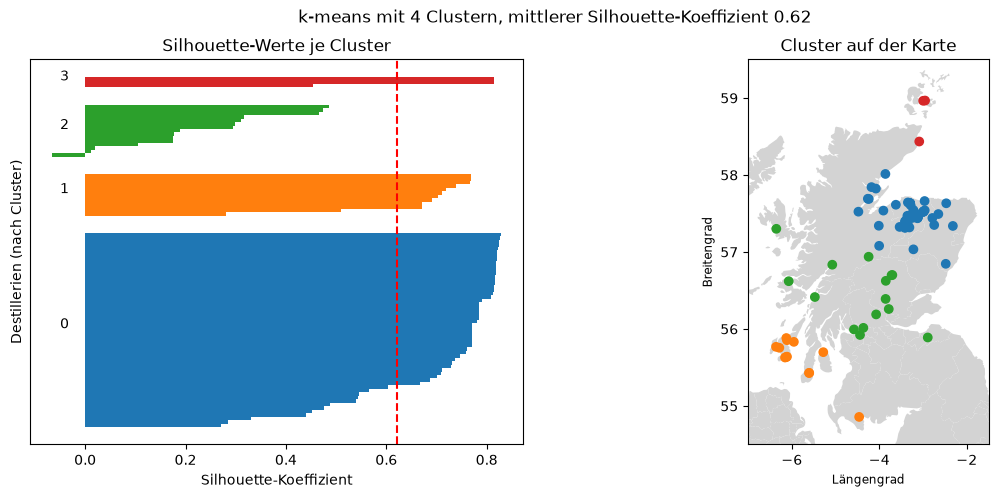

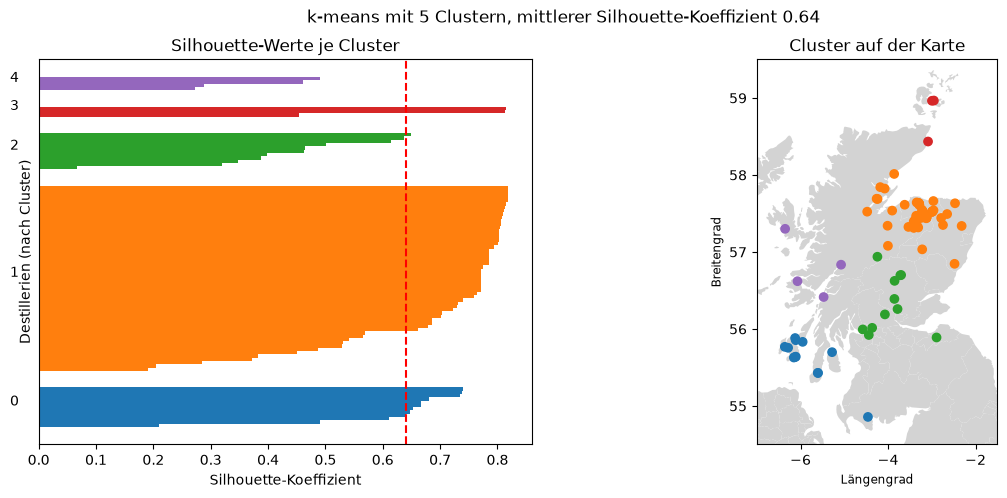

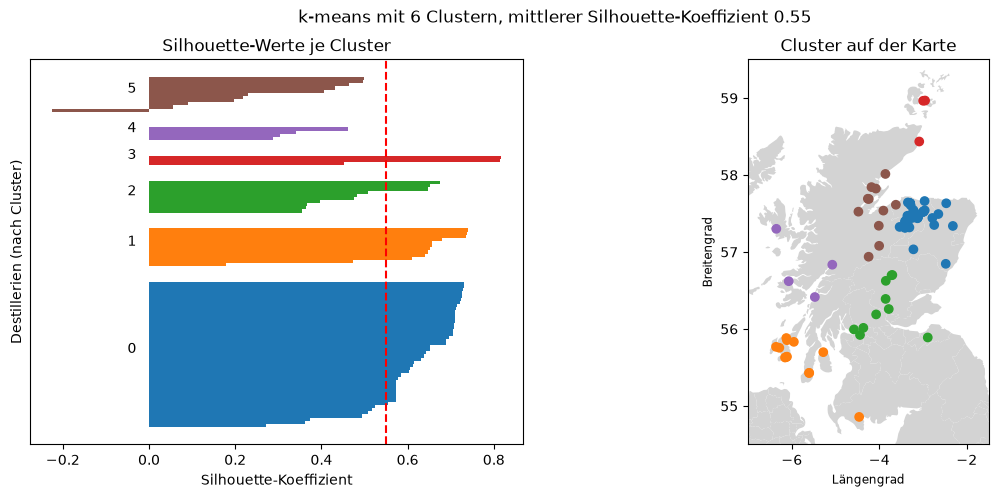

In [24]:
for n_clusters in range(2, 7):
    # k-means auf den Koordinaten in Kilometern
    labels = KMeans(n_clusters = n_clusters, n_init = 10, random_state = 0).fit_predict(x_geo)
    s = silhouette_samples(x_geo, labels) # Silhouette-Wert jeder Destillerie

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (14, 5))

    # Links: Silhouette-Werte, sortiert und nach Cluster gruppiert
    y_lower = 0
    for k in range(n_clusters):
        s_k = np.sort(s[labels == k])
        ax1.barh(range(y_lower, y_lower + len(s_k)), s_k, height = 1, color = f"C{k}")
        ax1.text(-0.05, y_lower + len(s_k) / 2, str(k)) # Nummer des Clusters
        y_lower += len(s_k) + 5 # Abstand zwischen den Clustern
    ax1.axvline(s.mean(), color = "red", linestyle = "--") # Durchschnitt
    ax1.set(title = "Silhouette-Werte je Cluster", xlabel = "Silhouette-Koeffizient",
            ylabel = "Destillerien (nach Cluster)", yticks = [])

    # Rechts: die Cluster auf der Karte
    ctry.plot(ax = ax2, color = "lightgrey")
    ax2.scatter(coords_new['Longitude'], coords_new['Latitude'], c = [f"C{k}" for k in labels])
    ax2.axis([-7, -1.5, 54.5, 59.5])
    ax2.set(title = "Cluster auf der Karte", xlabel = "Längengrad", ylabel = "Breitengrad")

    fig.suptitle(f"k-means mit {n_clusters} Clustern, mittlerer Silhouette-Koeffizient {s.mean():.2f}")
    plt.show()

Für jede Anzahl an Clustern zeigt die linke Grafik die Silhouette-Werte aller Destillerien, sortiert und nach Cluster gruppiert. Werte nahe 1 bedeuten, dass eine Destillerie gut in ihr Cluster passt und weit vom nächsten Cluster entfernt liegt. Werte nahe 0 liegen an der Grenze zwischen zwei Clustern, negative Werte deuten auf eine falsche Zuordnung hin. Die rote Linie ist der Durchschnitt. Die rechte Grafik zeigt die Cluster auf der Karte.

Der durchschnittliche Silhouette-Koeffizient ist bei 2 Clustern am höchsten (0,67): k-means trennt den Süden und Westen (Islay, Campbeltown, die Inseln und die Westküste, die Lowlands und das südliche Perthshire, 23 Destillerien) vom Norden mit der Speyside (63 Destillerien). Danach folgen 5 Cluster (0,64), 4 (0,62), 3 (0,60) und 6 Cluster (0,55). Negative Werte kommen nur vereinzelt vor, bei höchstens zwei Destillerien. Die Grafik für 5 Cluster zeigt gut, was die Werte bedeuten: Die Destillerien im Zentrum der Speyside haben Werte über 0,8, Destillerien am Rand eines Clusters deutlich niedrigere.

### Vergleich der Verfahren

Extrinsische Maße vergleichen ein Clustering mit einer bekannten Einteilung. Ein Beispiel ist der **Adjusted Rand Index** (ARI): Er prüft für alle Paare von Beobachtungen, ob sie in beiden Einteilungen gemeinsam oder getrennt sind. Der ARI ist 1, wenn die Einteilungen übereinstimmen (unabhängig von der Nummerierung der Cluster), und liegt nahe 0, wenn sie nicht mehr übereinstimmen, als bei zufälliger Zuordnung zu erwarten wäre.

Für die Whiskys gibt es keine Ground Truth. Wir können den ARI aber verwenden, um zu messen, wie ähnlich sich die Ergebnisse von k-means und dem agglomerativen Verfahren sind. Im Abschnitt zum Stochastic Block Model verwenden wir ihn mit einer echten Ground Truth.

In [25]:
# ARI zwischen k-means und dem agglomerativen Verfahren (je 3 Cluster)
adjusted_rand_score(labels_kmeans, labels_agglo)

0.6667941409812935

In [26]:
# Vergleiche die Zuordnungen von k-means (Zeilen) und dem agglomerativen Verfahren (Spalten)
pd.crosstab(labels_kmeans, labels_agglo, rownames = ['k-means'], colnames = ['Agglomerativ'])

Agglomerativ,0,1,2
k-means,,,
0,0,39,0
1,0,9,26
2,12,0,0


Der ARI zwischen k-means und dem agglomerativen Verfahren liegt bei 0,67, die beiden Einteilungen stimmen also nur teilweise überein. Die Kreuztabelle zeigt, woher der Unterschied kommt: Das Cluster der rauchigen Whiskys bzw. der Whiskys mit Tabaknote (12 Destillerien) ist bei beiden Verfahren identisch, und die 39 leichten Whiskys aus Cluster 0 von k-means landen alle im selben agglomerativen Cluster. Von den 35 vollmundigen Whiskys aus Cluster 1 von k-means ordnet das agglomerative Verfahren aber 9 den leichten Whiskys zu. Die Grenze zwischen leichten und vollmundigen Whiskys ist also unscharf, was zu den niedrigen Silhouette-Werten passt.

## DENCLUE

**DENCLUE** (*DENsity-based CLUstEring*) ist wie DBSCAN ein dichtebasiertes Verfahren, beschreibt die Dichte aber nicht über Nachbarn innerhalb eines festen Radius, sondern über eine glatte Dichtefunktion:

1. **Dichte schätzen:** Um jede Beobachtung legen wir eine Glockenkurve (Gauß-Kernel) mit Bandbreite $h$. Die Dichte an einem Punkt $p$ ist die Summe dieser Kurven:
$$f(p) = \sum_{i=1}^{n} \exp\left(-\frac{\lVert p - x_i \rVert^2}{2h^2}\right)$$
Jede Beobachtung in unmittelbarer Nähe von $p$ trägt fast 1 bei, weit entfernte Beobachtungen fast 0. $f(p)$ lässt sich also als „gewichtete Anzahl der Beobachtungen in der Nähe von $p$“ lesen.
2. **Bergsteigen (*Hill Climbing*):** Von jeder Beobachtung aus gehen wir schrittweise bergauf, bis wir ein lokales Maximum der Dichte erreichen. Dieses Maximum heißt **Dichte-Attraktor**.
3. **Cluster bilden:** Beobachtungen, die beim selben Attraktor ankommen, bilden ein Cluster. Ist die Dichte am Attraktor kleiner als ein Schwellenwert $\xi$ (*xi*), gelten die Beobachtungen als Rauschen.

Die beiden Parameter sind also die Bandbreite $h$ (wie glatt die Dichte ist) und der Schwellenwert $\xi$ (wie dicht ein Cluster mindestens sein muss).

`scikit-learn` enthält kein DENCLUE. Der Algorithmus ist aber kurz genug, um ihn selbst zu programmieren. Wir verwenden dieselben Koordinaten in Kilometern wie bei DBSCAN (`x_geo`).

In [27]:
def denclue_density(p, X, h):
    """Dichte am Punkt p: Summe der Gauß-Kernel um alle Beobachtungen in X."""
    squared_dist = ((X - p) ** 2).sum(axis = 1)
    return np.exp(-squared_dist / (2 * h ** 2)).sum()

def hill_climb(p, X, h, tol = 1e-4, max_iter = 1000):
    """Gehe von p aus bergauf, bis der Dichte-Attraktor erreicht ist."""
    for _ in range(max_iter):
        # Gewicht jeder Beobachtung: je näher an p, desto größer
        weights = np.exp(-((X - p) ** 2).sum(axis = 1) / (2 * h ** 2))
        # Neuer Punkt: gewichteter Mittelwert aller Beobachtungen (ein Schritt bergauf)
        p_new = (weights[:, None] * X).sum(axis = 0) / weights.sum()
        # Aufhören, wenn sich der Punkt kaum noch bewegt
        if np.linalg.norm(p_new - p) < tol:
            return p_new
        p = p_new
    return p

Der Schritt in `hill_climb` verschiebt den Punkt zum gewichteten Mittelwert der Beobachtungen, wobei nahe Beobachtungen stärker zählen. Dieser Schritt führt bei einem Gauß-Kernel immer bergauf (das Verfahren ist auch als *Mean Shift* bekannt).

Nun führen wir das Bergsteigen für jede Destillerie durch. Als Bandbreite wählen wir $h = 15$ km.

In [28]:
h = 15 # Bandbreite in km
X_geo = x_geo.to_numpy()

# Finde für jede Destillerie ihren Dichte-Attraktor
attractors = np.array([hill_climb(x_i, X_geo, h) for x_i in X_geo])

# Runde auf ganze km: Destillerien mit demselben Attraktor haben dann exakt dieselben Koordinaten
attractors = attractors.round(0)
unique_attractors, attractor_id = np.unique(attractors, axis = 0, return_inverse = True)

# Dichte an jedem Attraktor und Anzahl der Destillerien, die dort ankommen
attractor_table = pd.DataFrame({
    'Dichte': [denclue_density(a, X_geo, h) for a in unique_attractors],
    'Destillerien': np.bincount(attractor_id)
}).round(2)
attractor_table.sort_values('Dichte', ascending = False)

,Dichte,Destillerien
12,28.47,48
1,5.54,8
8,3.76,6
11,2.94,3
7,2.77,3
10,2.29,3
3,2.16,3
15,1.99,2
9,1.65,2
2,1.02,1


Das Bergsteigen endet an 17 verschiedenen Attraktoren. Der Attraktor mit der weitaus höchsten Dichte (rund 28) zieht 48 Destillerien an, das ist die Speyside. Danach folgen einige Attraktoren mit mittlerer Dichte zwischen etwa 1,6 und 5,5, die jeweils 2 bis 8 Destillerien anziehen. Am Ende stehen mehrere Attraktoren mit einer Dichte von etwa 1: Das sind Destillerien, die allein liegen und deren Dichte fast nur aus ihrem eigenen Beitrag (1) besteht.

Als Schwellenwert wählen wir $\xi = 2{,}5$: Ein Cluster muss am Attraktor mindestens die Dichte von zweieinhalb Destillerien in unmittelbarer Nähe haben.

In [29]:
xi = 2.5 # Schwellenwert für die Dichte am Attraktor

# Attraktoren mit ausreichender Dichte bilden Cluster, nummeriert nach absteigender Dichte
dense = attractor_table[attractor_table['Dichte'] >= xi].sort_values('Dichte', ascending = False)
cluster_of_attractor = {a: k for k, a in enumerate(dense.index)}

# Label jeder Destillerie: Cluster ihres Attraktors oder -1 für Rauschen
pred_denclue = np.array([cluster_of_attractor.get(a, -1) for a in attractor_id])

# Anzahl der Destillerien je Cluster (-1 = Rauschen)
pd.Series(pred_denclue).value_counts().sort_index()

-1    18
 0    48
 1     8
 2     6
 3     3
 4     3
Name: count, dtype: int64

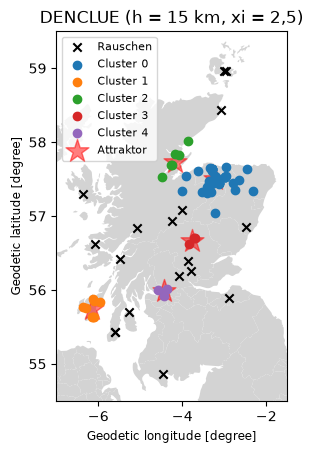

In [30]:
# Rechne die Attraktoren für die Karte in Längen- und Breitengrade um (Koordinaten in Metern)
attr_lon, attr_lat = transformer.transform(unique_attractors[dense.index, 0] * 1000,
                                           unique_attractors[dense.index, 1] * 1000)

# Plotte Landkarte von UK
ctry.plot(color = "lightgrey")

# Rauschen (Label -1) in Schwarz
noise = pred_denclue == -1
plt.scatter(x = coords_new.loc[noise, 'Longitude'], y = coords_new.loc[noise, 'Latitude'],
            marker = 'x', c = "black", label = "Rauschen")

# Cluster in Farbe
for label in sorted(set(pred_denclue) - {-1}):
    sel = pred_denclue == label
    plt.scatter(x = coords_new.loc[sel, 'Longitude'], y = coords_new.loc[sel, 'Latitude'],
                marker = 'o', label = "Cluster " + str(label), zorder = 3)

# Dichte-Attraktoren als Sterne (hinter den Punkten)
plt.scatter(attr_lon, attr_lat, marker = '*', s = 300, c = "red", alpha = 0.5, label = "Attraktor", zorder = 2)

# Trimme die Grafik
plt.axis([-7, -1.5, 54.5, 59.5])
plt.legend(loc = "upper left", fontsize = 8)
plt.title("DENCLUE (h = 15 km, xi = 2,5)")
plt.show()

DENCLUE findet fünf Cluster: die Speyside (48 Destillerien), Islay (8), eine Gruppe nördlich von Inverness am Cromarty und Dornoch Firth (6) sowie zwei kleine Gruppen mit je 3 Destillerien in Perthshire und im Raum Glasgow. 18 Destillerien gelten als Rauschen. Die roten Sterne (hinter den Punkten) markieren die Dichte-Attraktoren, also die „Gipfel“ der Dichte, zu denen die Destillerien eines Clusters hinaufsteigen.

**Vergleich mit DBSCAN:**

* DBSCAN hat die Speyside und die Gruppe nördlich von Inverness zu einem großen Cluster verbunden, weil eine Kette von Destillerien mit Abständen unter 30 km die beiden Regionen verbindet. Bei DENCLUE liegt zwischen den beiden Regionen ein Tal in der Dichte, deshalb steigen die Destillerien zu verschiedenen Gipfeln auf.
* Jedes Cluster hat bei DENCLUE ein Zentrum (den Attraktor). Neue Beobachtungen könnte man deshalb einem Cluster zuordnen, indem man auch von ihnen aus bergauf geht.
* Wie bei DBSCAN hängt das Ergebnis stark von den Parametern ab: Mit größerem $h$ wird die Dichte glatter, und benachbarte Gipfel verschmelzen. Ein kleineres $\xi$ macht aus mehr kleinen Gruppen eigene Cluster.

*Hinweis:* Das ursprüngliche DENCLUE verbindet zusätzlich Attraktoren, zwischen denen ein Weg mit Dichte über $\xi$ existiert. Diesen Schritt lassen wir hier der Einfachheit halber weg.

## Netzwerkanalyse

Bisher haben wir Beobachtungen anhand ihrer Merkmale analysiert. Oft liegen Daten aber als **Netzwerk** vor: Knoten (z. B. Personen, Webseiten, Unternehmen) und Kanten zwischen ihnen (Freundschaften, Links, Geschäftsbeziehungen). Das Paket `networkx` enthält viele Funktionen für die Arbeit mit Netzwerken.

### Ein Netzwerk der Whiskys

Die Whisky-Daten sind kein Netzwerk, wir können aber eines daraus bauen: Wir verbinden jede Destillerie mit den 5 Destillerien, deren Geschmacksprofil ihr am ähnlichsten ist (*k-Nearest-Neighbour-Graph*). Dafür verwenden wir dieselben skalierten Geschmacksmerkmale wie für k-means. Das Netzwerk ist **gerichtet**: Eine Kante von A nach B bedeutet „B gehört zu den 5 ähnlichsten Whiskys von A“, das muss umgekehrt nicht gelten.

In [31]:
# Adjazenzmatrix: Zeile i hat eine 1 bei den 5 ähnlichsten Destillerien von Destillerie i
# (dieselben skalierten Geschmacksmerkmale wie bei k-means)
A_knn = kneighbors_graph(x_scaled, n_neighbors = 5, include_self = False).toarray()

# Erstelle daraus ein gerichtetes networkx-Netzwerk
G_knn = nx.from_numpy_array(A_knn, create_using = nx.DiGraph)
print("Anzahl der Knoten:", G_knn.number_of_nodes())
print("Anzahl der Kanten:", G_knn.number_of_edges())

Anzahl der Knoten: 86
Anzahl der Kanten: 430


Das Netzwerk hat 86 Knoten (Destillerien) und 86 × 5 = 430 gerichtete Kanten, weil jede Destillerie genau 5 Nachbarn auswählt. Wie oft eine Destillerie *von anderen* als Nachbar ausgewählt wird, ist dagegen unterschiedlich.

Weil die Geschmacksmerkmale nur ganze Werte haben, sind oft mehrere Destillerien gleich weit entfernt. Welche davon als 5. Nachbar gewählt wird, kann je nach Version von `scikit-learn` variieren, und damit auch die Ergebnisse dieses Abschnitts im Detail.

### PageRank

PageRank wurde von den Gründern von Google entwickelt, um die Bedeutung von Webseiten zu bewerten. Die Idee: Eine Seite ist wichtig, wenn viele *wichtige* Seiten auf sie verlinken. Man kann sich das als zufälligen Surfer vorstellen:

* Er startet auf einer zufälligen Seite und folgt mit Wahrscheinlichkeit 0,85 (Parameter `alpha`, der *Dämpfungsfaktor*) einem zufälligen Link auf der aktuellen Seite.
* Mit Wahrscheinlichkeit 1 − `alpha` = 0,15 springt er stattdessen auf eine völlig zufällige Seite.

Der PageRank einer Seite ist der Anteil der Zeit, den der Surfer auf lange Sicht auf dieser Seite verbringt. Die Werte aller Knoten summieren sich daher zu 1.

In unserem Netzwerk „surft“ man von einem Whisky zu einem seiner ähnlichsten Whiskys. Ein hoher PageRank bedeutet also: Dieser Whisky wird oft als ähnlich genannt, und zwar von Whiskys, die selbst oft genannt werden.

In [32]:
# Berechne den PageRank jedes Knotens
pagerank = pd.Series(nx.pagerank(G_knn, alpha = 0.85))

# Stelle das Ergebnis mit den Namen der Destillerien und der Anzahl eingehender Kanten zusammen
pr = pd.DataFrame({'Distillery': df['Distillery'],
                   'PageRank': pagerank,
                   'Eingehende Kanten': A_knn.sum(axis = 0)}) # Spaltensumme = wie oft als Nachbar gewählt
pr = pr.sort_values('PageRank', ascending = False)

# Die 10 Destillerien mit dem höchsten PageRank
pr.head(10)

,Distillery,PageRank,Eingehende Kanten
41,Glenallachie,0.044059,15.0
52,Glenturret,0.042882,14.0
60,Loch Lomond,0.040794,14.0
15,Benromach,0.039592,15.0
81,Tobermory,0.035623,10.0
17,BlairAthol,0.034297,12.0
22,Cardhu,0.034161,10.0
0,Aberfeldy,0.033434,11.0
49,Glenlossie,0.029792,9.0
7,Auchroisk,0.024184,11.0


In [33]:
# Die 8 Destillerien mit dem niedrigsten PageRank
pr.tail(8)

,Distillery,PageRank,Eingehende Kanten
42,Glendronach,0.002153,1.0
31,Edradour,0.002101,1.0
61,Longmorn,0.002101,1.0
65,Mortlach,0.002041,1.0
10,Balmenach,0.001744,0.0
1,Aberlour,0.001744,0.0
34,GlenGarioch,0.001744,0.0
80,Teaninich,0.001744,0.0


Bei 86 Destillerien läge der durchschnittliche PageRank bei 1/86 ≈ 0,012. Glenallachie, Glenturret und Loch Lomond erreichen rund 0,04, also mehr als das Dreifache. Sie werden von 14 oder 15 anderen Destillerien als ähnlich genannt. Ihre Geschmacksprofile sind ausgewogen, mit mittleren Werten bei fast allen Merkmalen: Sie sind gewissermaßen die „typischen“ schottischen Whiskys.

Am unteren Ende stehen Destillerien, die kaum oder nie als Nachbar gewählt werden. Aberlour, Balmenach, Glen Garioch und Teaninich haben keine einzige eingehende Kante. Ihr PageRank von 0,0017 entspricht genau dem Anteil, den sie allein durch die zufälligen Sprünge erhalten (0,15/86). Diese Whiskys haben ein eigenständiges Profil, das keinem anderen sehr nahe kommt.

PageRank und die Anzahl der eingehenden Kanten hängen eng zusammen, sind aber nicht dasselbe: Benromach hat genauso viele eingehende Kanten wie Glenallachie (15), steht aber nur auf Platz 4, weil seine Kanten von weniger zentralen Whiskys kommen.

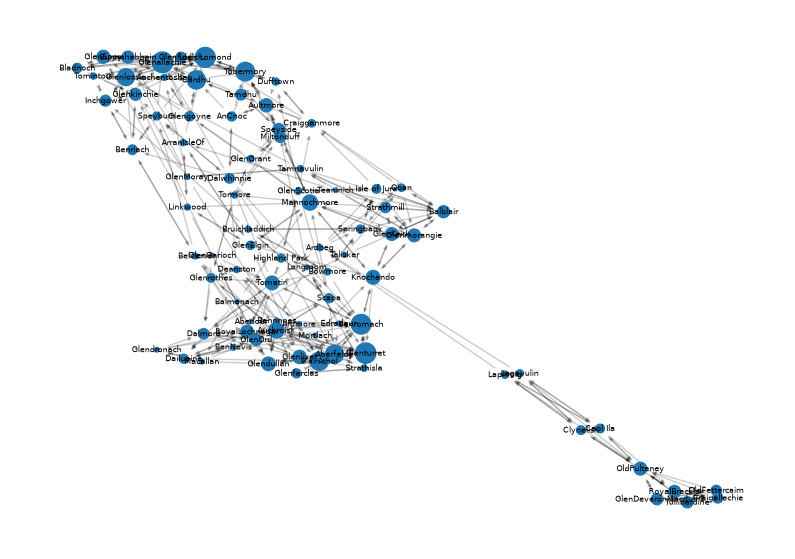

In [34]:
# Zeichne das Netzwerk: Größe der Knoten proportional zum PageRank
pos_knn = nx.spring_layout(G_knn, seed = 0) # Positionen: verbundene Knoten liegen nahe beieinander

plt.figure(figsize = (10, 7))
nx.draw_networkx_edges(G_knn, pos_knn, alpha = 0.2, arrowsize = 5)
nx.draw_networkx_nodes(G_knn, pos_knn, node_size = pagerank * 5000, node_color = "tab:blue")
nx.draw_networkx_labels(G_knn, pos_knn, labels = dict(enumerate(df['Distillery'])), font_size = 6)
plt.axis("off")
plt.show()

Die großen Knoten mit hohem PageRank liegen im dicht vernetzten Zentrum des Netzwerks. Kleine Knoten am Rand sind Whiskys mit ungewöhnlichem Profil. Etwas abseits liegt eine eigene Gruppe, die vor allem untereinander verbunden ist: die Whiskys mit Tabaknote. Diese Gruppen schauen wir uns im nächsten Abschnitt genauer an.

## Stochastic Block Model

Auch in Netzwerken können wir nach Clustern suchen: Gruppen von Knoten, die ähnlich vernetzt sind.

Das **Stochastic Block Model** (SBM) ist ein Wahrscheinlichkeitsmodell für solche Netzwerke:

* Jeder Knoten gehört zu genau einem von $K$ Blöcken (Clustern).
* Die Wahrscheinlichkeit, dass zwischen zwei Knoten eine Kante besteht, hängt *nur* von den Blöcken der beiden Knoten ab. Sie steht in einer $K \times K$-Matrix $P$: $P_{rs}$ ist die Wahrscheinlichkeit für eine Kante zwischen einem Knoten aus Block $r$ und einem Knoten aus Block $s$.

Sind die Werte auf der Diagonale von $P$ groß und die übrigen klein, sind die Knoten innerhalb eines Blocks dicht vernetzt und zwischen den Blöcken kaum (*Communities*). Das SBM kann aber auch andere Strukturen abbilden, etwa Blöcke, deren Knoten vor allem mit Knoten aus *anderen* Blöcken verbunden sind.

Wir gehen in zwei Schritten vor: Zuerst simulieren wir ein Netzwerk aus einem SBM, dessen Blöcke wir kennen, und prüfen, ob wir sie wiederfinden. Danach wenden wir das Modell auf das Whisky-Netzwerk an.

### Simulation eines Netzwerks

Das Paket `networkx` enthält Funktionen für die Arbeit mit Netzwerken, darunter `stochastic_block_model`, das ein zufälliges Netzwerk aus einem SBM erzeugt.

In [35]:
# Drei Blöcke mit je 30 Knoten
sizes = [30, 30, 30]

# Kantenwahrscheinlichkeiten: 30 % innerhalb eines Blocks, 2 % zwischen den Blöcken
P = [[0.30, 0.02, 0.02],
     [0.02, 0.30, 0.02],
     [0.02, 0.02, 0.30]]

# Simuliere das Netzwerk (seed macht das Ergebnis reproduzierbar)
G = nx.stochastic_block_model(sizes, P, seed = 0)

# Die wahren Blöcke der Knoten: die ersten 30 Knoten in Block 0, die nächsten 30 in Block 1 usw.
blocks_true = np.repeat([0, 1, 2], sizes)

print("Anzahl der Knoten:", G.number_of_nodes())
print("Anzahl der Kanten:", G.number_of_edges())

Anzahl der Knoten: 90
Anzahl der Kanten: 449


Ein Netzwerk lässt sich als **Adjazenzmatrix** $A$ darstellen: $A_{ij} = 1$, wenn zwischen Knoten $i$ und $j$ eine Kante besteht, sonst 0. In der linken Grafik sind die Knoten nach ihren Blöcken sortiert. In der Praxis kennen wir die Blöcke aber nicht, und die Knoten liegen in beliebiger Reihenfolge vor. Das zeigt die rechte Grafik, in der wir die Reihenfolge der Knoten zufällig vertauscht haben.

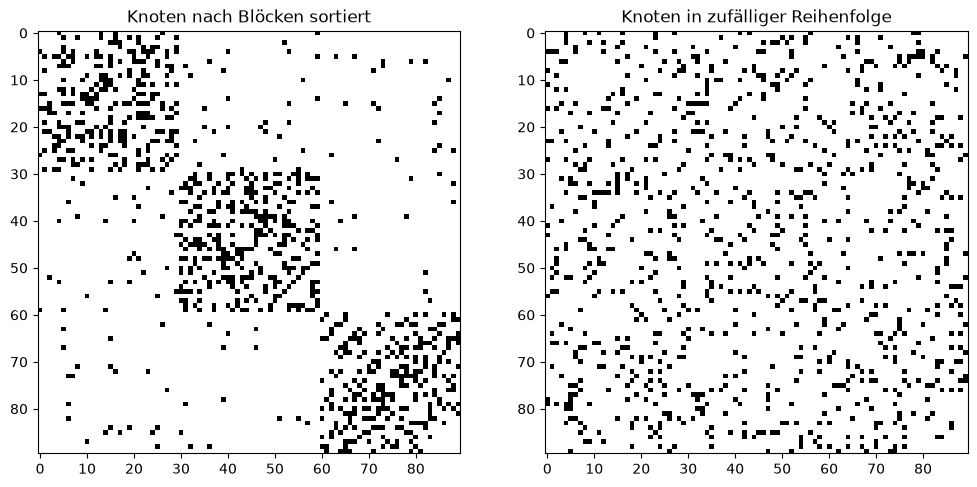

In [36]:
# Adjazenzmatrix als NumPy-Array
A = nx.to_numpy_array(G)

# Vertausche die Reihenfolge der Knoten zufällig
rng = np.random.default_rng(0)
order = rng.permutation(len(A))
A_perm = A[np.ix_(order, order)] # Zeilen und Spalten in der neuen Reihenfolge
blocks_true_perm = blocks_true[order]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (12, 6))
ax1.imshow(A, cmap = "Greys")
ax1.set_title("Knoten nach Blöcken sortiert")
ax2.imshow(A_perm, cmap = "Greys")
ax2.set_title("Knoten in zufälliger Reihenfolge")
plt.show()

Das Netzwerk hat 90 Knoten und 449 Kanten. Links sind die drei Blöcke als dunkle Quadrate auf der Diagonale gut zu erkennen: Innerhalb der Blöcke gibt es viele Kanten, dazwischen nur vereinzelte Punkte. Rechts enthält die Matrix genau dieselben Kanten, aber die Struktur ist nicht mehr zu sehen. Aufgabe der Schätzung ist es, die Blöcke aus dieser ungeordneten Matrix wiederzufinden.

### Schätzung der Blöcke

Um ein SBM zu schätzen, müssen wir die Blockzugehörigkeit der Knoten und die Matrix $P$ bestimmen. Für die Blöcke verwenden wir **Spectral Clustering**: Das Verfahren berechnet aus der Adjazenzmatrix für jeden Knoten einige Koordinaten (aus den Eigenvektoren der Matrix) und gruppiert die Knoten anschließend mit k-means. Für Netzwerke, die aus einem SBM stammen, findet es die Blöcke zuverlässig, wenn die Blöcke ausreichend dicht vernetzt sind. Mit `affinity = 'precomputed'` teilen wir `scikit-learn` mit, dass wir direkt die Adjazenzmatrix übergeben.

Wie bei k-means müssen wir die Anzahl der Blöcke vorgeben.

In [37]:
# Erstelle ein 'leeres' Modell mit 3 Blöcken
spectral = SpectralClustering(n_clusters = 3, affinity = 'precomputed', random_state = 0)

# Schätze die Blöcke aus der ungeordneten Adjazenzmatrix
blocks_est = spectral.fit_predict(A_perm)

# Vergleiche wahre (Zeilen) und geschätzte Blöcke (Spalten)
pd.crosstab(blocks_true_perm, blocks_est, rownames = ['wahr'], colnames = ['geschätzt'])

geschätzt,0,1,2
wahr,,,
0,0,30,0
1,30,0,0
2,0,0,30


Jeder wahre Block landet vollständig in genau einem geschätzten Block: Alle 90 Knoten werden richtig zugeordnet. Dass die Nummern der Blöcke nicht übereinstimmen (z. B. wahrer Block 0 = geschätzter Block 1), spielt keine Rolle, denn die Nummerierung von Clustern ist immer willkürlich.

Der Adjusted Rand Index (ARI) aus dem Abschnitt zur Evaluation berücksichtigt diese Umbenennung. Hier gibt es eine echte Ground Truth, und der ARI zeigt eine perfekte Übereinstimmung:

In [38]:
adjusted_rand_score(blocks_true_perm, blocks_est)

1.0

Mit den geschätzten Blöcken können wir auch die Matrix $P$ schätzen: Für jedes Paar von Blöcken teilen wir die Anzahl der vorhandenen Kanten durch die Anzahl der möglichen Kanten.

In [39]:
def block_matrix(A, blocks):
    """Schätze die Kantenwahrscheinlichkeiten zwischen den Blöcken."""
    K = blocks.max() + 1
    P_est = np.zeros((K, K))
    for r in range(K):
        for s in range(K):
            in_r = blocks == r
            in_s = blocks == s
            # Anzahl der Kanten zwischen Block r und Block s
            edges = A[np.ix_(in_r, in_s)].sum()
            # Anzahl der möglichen Kanten (innerhalb eines Blocks ohne Kanten eines Knotens zu sich selbst)
            possible = in_r.sum() * in_s.sum() - (in_r.sum() if r == s else 0)
            P_est[r, s] = edges / possible
    return pd.DataFrame(P_est).round(3)

block_matrix(A_perm, blocks_est)

,0,1,2
0,0.331,0.032,0.014
1,0.032,0.280,0.023
2,0.014,0.023,0.276


Die geschätzten Wahrscheinlichkeiten liegen nahe an den wahren Werten: rund 0,3 innerhalb der Blöcke (0,28 bis 0,33) und rund 0,02 zwischen den Blöcken (0,01 bis 0,03). Die Abweichungen entstehen durch den Zufall bei der Simulation. Die Reihenfolge der Zeilen und Spalten folgt der Nummerierung der geschätzten Blöcke.

### Anwendung: ein Netzwerk der Whiskys

Nun suchen wir im Whisky-Netzwerk aus dem Abschnitt zu PageRank nach Blöcken. Das SBM in dieser einfachen Form ist für ungerichtete Netzwerke gedacht. Deshalb verbinden wir zwei Destillerien, sobald mindestens eine die andere als Nachbarn hat, und suchen dann drei Blöcke.

In [40]:
# Mache das Netzwerk ungerichtet: Eine Kante besteht, wenn mindestens eine der beiden
# Destillerien die andere als Nachbarn hat
A_whisky = np.maximum(A_knn, A_knn.T)

# Erstelle daraus ein ungerichtetes networkx-Netzwerk
G_whisky = nx.from_numpy_array(A_whisky)
print("Anzahl der Knoten:", G_whisky.number_of_nodes())
print("Anzahl der Kanten:", G_whisky.number_of_edges())
print("Zusammenhängende Teilnetzwerke:", nx.number_connected_components(G_whisky))

Anzahl der Knoten: 86
Anzahl der Kanten: 310
Zusammenhängende Teilnetzwerke: 1


In [41]:
# Schätze drei Blöcke
spectral_whisky = SpectralClustering(n_clusters = 3, affinity = 'precomputed', random_state = 0)
blocks_whisky = spectral_whisky.fit_predict(A_whisky)

# Anzahl der Destillerien je Block
pd.Series(blocks_whisky).value_counts().sort_index()

0    33
1    43
2    10
Name: count, dtype: int64

Das ungerichtete Netzwerk hat 86 Knoten und 310 Kanten und ist zusammenhängend: Von jeder Destillerie aus kann man über Kanten jede andere erreichen. Es hat weniger als 430 Kanten, weil zwei Destillerien, die sich gegenseitig als Nachbarn haben, nur eine gemeinsame Kante bekommen. Die drei Blöcke haben 33, 43 und 10 Destillerien.

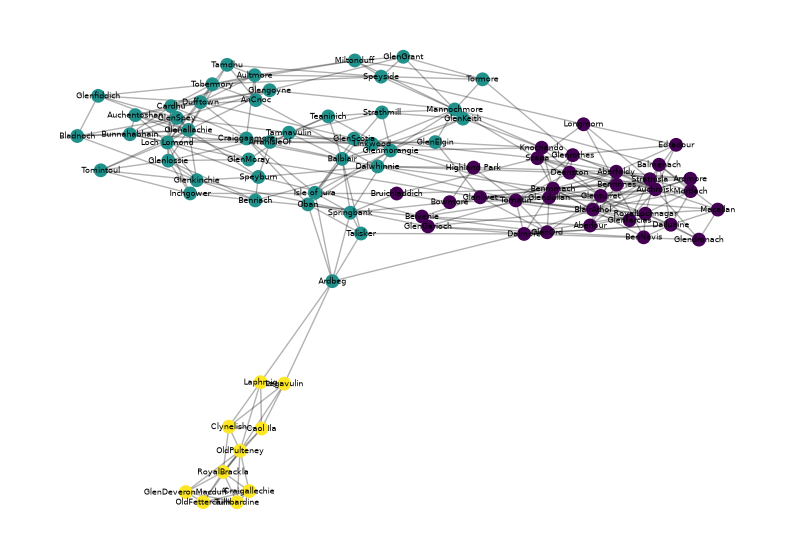

In [42]:
# Zeichne das Netzwerk, eingefärbt nach Block
pos = nx.spring_layout(G_whisky, seed = 0) # Positionen der Knoten: verbundene Knoten liegen nahe beieinander

plt.figure(figsize = (10, 7))
nx.draw_networkx_edges(G_whisky, pos, alpha = 0.3)
nx.draw_networkx_nodes(G_whisky, pos, node_color = blocks_whisky, cmap = "viridis", node_size = 80)
nx.draw_networkx_labels(G_whisky, pos, labels = dict(enumerate(df['Distillery'])), font_size = 6)
plt.axis("off")
plt.show()

In [43]:
# Geschätzte Kantenwahrscheinlichkeiten zwischen den Blöcken
block_matrix(A_whisky, blocks_whisky)

,0,1,2
0,0.218,0.018,0.000
1,0.018,0.156,0.005
2,0.000,0.005,0.600


In [44]:
# Durchschnittliches Geschmacksprofil je Block (Originalskala 0 bis 4)
x.groupby(blocks_whisky).mean().round(2)

,Body,Smoky,Medicinal,Tobacco,Honey,Spicy,Winey,Nutty,Malty,Floral
0,2.55,1.61,0.18,0.0,1.82,1.67,1.70,1.76,2.06,1.67
1,1.60,1.28,0.56,0.0,0.95,1.14,0.42,1.30,1.63,1.84
2,2.50,2.40,1.70,1.0,0.60,1.50,1.00,1.20,1.70,1.20


Die Blöcke lassen sich über ihr durchschnittliches Geschmacksprofil interpretieren:

* **Block 2** enthält genau die 10 Destillerien mit Tabaknote (`Tobacco` = 1), darunter Caol Ila, Lagavulin und Laphroaig. Da `Tobacco` nur die Werte 0 und 1 hat, liegen diese Whiskys nach der Skalierung weit von allen anderen entfernt. Innerhalb dieses Blocks ist das Netzwerk sehr dicht (Kantenwahrscheinlichkeit 0,6), zu Block 1 gibt es nur vereinzelte und zu Block 0 gar keine Kanten.
* **Block 0** enthält vollmundige Whiskys mit mehr Weinnote, Honig und Nussigkeit (`Body` 2,6, `Winey` 1,7).
* **Block 1** enthält leichtere Whiskys (`Body` 1,6) mit wenig Weinnote, dafür eher blumig.

Die Matrix der Kantenwahrscheinlichkeiten zeigt das typische Bild von Communities: hohe Werte auf der Diagonale, sehr niedrige außerhalb. Wie im Dendrogramm (die Gruppe mit Tabaknote im rauchigen Ast) und später in der Merkmalsauswahl zeigt sich, dass `Tobacco` die Whiskys stark trennt. Auffällig ist, dass Ardbeg trotz seines rauchigen Profils in Block 1 landet: Im k-Nearest-Neighbour-Graph zählt nur, wer die nächsten Nachbarn sind, und Ardbeg hat keine Tabaknote.

Im Vergleich zu k-means arbeitet das SBM nicht direkt mit den Merkmalen, sondern nur mit den Verbindungen im Netzwerk. Es eignet sich deshalb vor allem für Daten, die von vornherein als Netzwerk vorliegen.

## Merkmalsauswahl (Feature Selection)

Welche Merkmale sind für die Bildung der Cluster eigentlich wichtig? Dafür gehen wir so vor:

1. Wir trainieren k-means mit 2 bis 6 Clustern, jeweils 10-mal (da k-means von zufälligen Startwerten abhängt). Neben den Geschmacksmerkmalen verwenden wir diesmal auch die Koordinaten, die wir zur Klarheit in `Ost` und `Nord` umbenennen. `Medicinal`, `Sweetness` und `Fruity` lassen wir weg.
2. Für jedes Cluster bilden wir eine binäre Variable: 1, wenn eine Destillerie im Cluster liegt, sonst 0.
3. Mit `mutual_info_classif` messen wir für jedes Merkmal die *Mutual Information* mit dieser Variable. Sie ist 0, wenn das Merkmal nichts über die Zugehörigkeit zum Cluster verrät, und umso größer, je besser das Merkmal das Cluster vom Rest unterscheidet.

Das Ergebnis `result` hat eine Zeile pro Cluster: (2 + 3 + 4 + 5 + 6) × 10 = 200 Zeilen. Die Spalten `ncluster` und `group` geben an, aus welchem Modell und welchem Cluster die Zeile stammt.

In [45]:
# Wähle die Merkmale aus (diesmal inklusive Koordinaten) und skaliere sie auf [0, 1]
# Eigene Variablennamen, damit x und x_scaled (Geschmack) erhalten bleiben
x_fs = df.drop(columns = ['RowID', 'Distillery', 'Postcode', 'Medicinal', 'Sweetness', 'Fruity'])
x_fs = x_fs.rename(columns = {'Latitude': 'Ost', 'Longitude': 'Nord'}) # Die Spaltennamen im Datensatz sind vertauscht
x_fs_scaled = preprocessing.MinMaxScaler().fit_transform(x_fs)

result = []
for n_clusters in range(2, 7):
    for seed in range(10): # 10 Modelle mit verschiedenen Startwerten
        labels = KMeans(n_clusters = n_clusters, n_init = 'auto', random_state = seed).fit_predict(x_fs_scaled)
        for group in range(n_clusters):
            in_group = (labels == group).astype(int) # 1 = im Cluster, 0 = nicht im Cluster
            # Mutual Information zwischen jedem Merkmal und der Clusterzugehörigkeit
            mi = mutual_info_classif(x_fs_scaled, in_group, random_state = 0)
            result.append({**dict(zip(x_fs.columns, mi)), 'ncluster': n_clusters, 'group': group})

result = pd.DataFrame(result)
result

,Body,Smoky,Tobacco,Honey,Spicy,Winey,Nutty,Malty,Floral,Ost,Nord,ncluster,group
0,0.182379,0.127070,0.130559,0.025875,0.132162,0.074727,0.067115,0.000000,0.011185,0.156539,0.000000,2,0
1,0.182379,0.127070,0.130559,0.025875,0.132162,0.074727,0.067115,0.000000,0.011185,0.156539,0.000000,2,1
2,0.249918,0.112103,0.045889,0.079984,0.079818,0.158121,0.084735,0.119855,0.112767,0.101011,0.049999,2,0
3,0.249918,0.112103,0.045889,0.079984,0.079818,0.158121,0.084735,0.119855,0.112767,0.101011,0.049999,2,1
4,0.066000,0.111628,0.309290,0.096698,0.000000,0.000000,0.000000,0.000000,0.076415,0.070197,0.006212,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,0.013647,0.074037,0.026143,0.029037,0.000000,0.007708,0.000000,0.089102,0.003423,0.175819,0.068059,6,1
196,0.029512,0.119997,0.205796,0.085592,0.006062,0.000000,0.015602,0.199595,0.024367,0.005156,0.000000,6,2
197,0.259895,0.169752,0.294335,0.000000,0.000000,0.056928,0.000000,0.036390,0.000000,0.026399,0.000000,6,3
198,0.081508,0.000000,0.000000,0.052930,0.048051,0.058310,0.000000,0.018026,0.012155,0.170239,0.158094,6,4


In [46]:
# Kennzahlen der Mutual Information je Merkmal über alle 200 Cluster
result.describe()

,Body,Smoky,Tobacco,Honey,Spicy,Winey,Nutty,Malty,Floral,Ost,Nord,ncluster,group
count,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean,0.106855,0.072987,0.100170,0.063777,0.063565,0.092309,0.025792,0.045251,0.033897,0.097339,0.068116,4.500000,1.750000
std,0.088901,0.071522,0.124987,0.056551,0.084079,0.092306,0.039390,0.055279,0.037805,0.093079,0.061823,1.326195,1.482731
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000
25%,0.028699,0.010629,0.004127,0.001674,0.000669,0.006553,0.000000,0.000000,0.001010,0.021387,0.006135,3.750000,0.750000
50%,0.076445,0.058326,0.033016,0.059493,0.032587,0.056928,0.011394,0.031316,0.024186,0.070673,0.057663,5.000000,1.500000
75%,0.180650,0.116570,0.169168,0.097564,0.080360,0.158121,0.035798,0.065396,0.051379,0.142578,0.101886,6.000000,3.000000
max,0.300645,0.263936,0.365357,0.264432,0.352384,0.305318,0.184797,0.268523,0.163265,0.379545,0.259093,6.000000,5.000000


Die Tabelle fasst die 200 Zeilen von `result` je Merkmal zusammen. Im Mittel haben `Body` (0,11), `Tobacco` (0,10), `Ost` (0,10) und `Winey` (0,09) die höchste Mutual Information. `Nutty` und `Floral` (je 0,03) tragen am wenigsten zur Trennung der Cluster bei. Auffällig sind die hohen Maxima bei `Tobacco` (0,37) und `Ost` (0,38): Manche Cluster werden fast vollständig durch ein einziges Merkmal bestimmt.

Dass die Koordinaten, vor allem der Ost-Wert, eine hohe Mutual Information haben, ist dagegen wenig überraschend: Sie gehen selbst in die Clusterbildung ein. Ob Geschmack und Herkunftsregion zusammenhängen, lässt sich daraus nicht schließen. Dafür müsste man z. B. die Geschmackscluster mit den Regionen vergleichen.

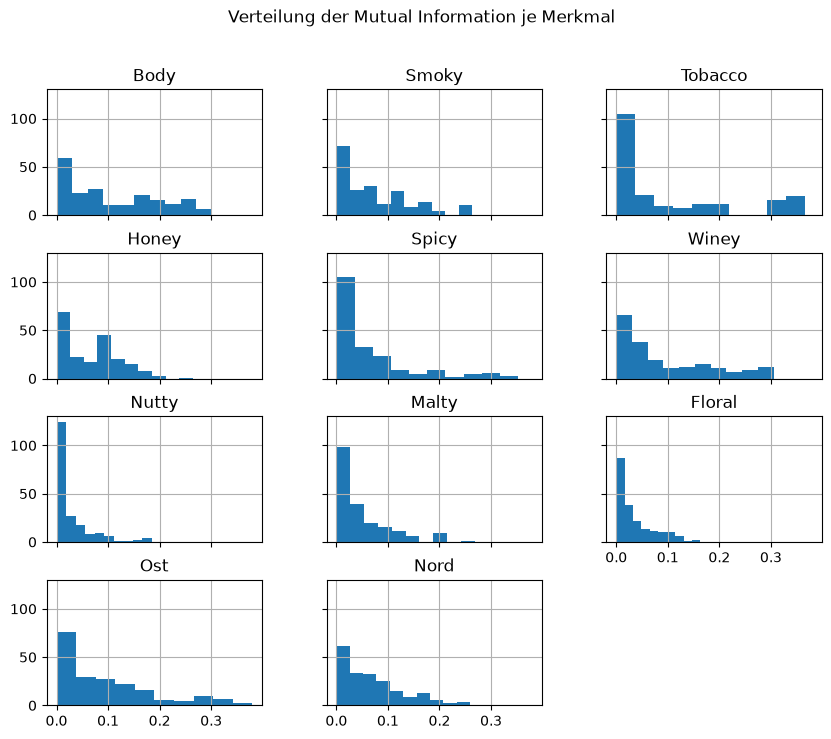

In [47]:
# Verteilung der Mutual Information je Merkmal
result.drop(["ncluster", "group"], axis = 1).hist(sharex = True, sharey = True, figsize = (10, 8))
plt.suptitle('Verteilung der Mutual Information je Merkmal')
plt.show()

Bei den meisten Merkmalen liegt die Mutual Information für die meisten Cluster nahe 0: Ein Merkmal ist also meist nur für einzelne Cluster wichtig. `Tobacco` fällt durch eine zweigipflige Verteilung auf. Entweder spielt das Merkmal für ein Cluster kaum eine Rolle, oder es ist mit Werten um 0,35 sehr wichtig. Das passt dazu, dass nur wenige Whiskys eine Tabaknote haben und diese häufig ein eigenes Cluster bilden.

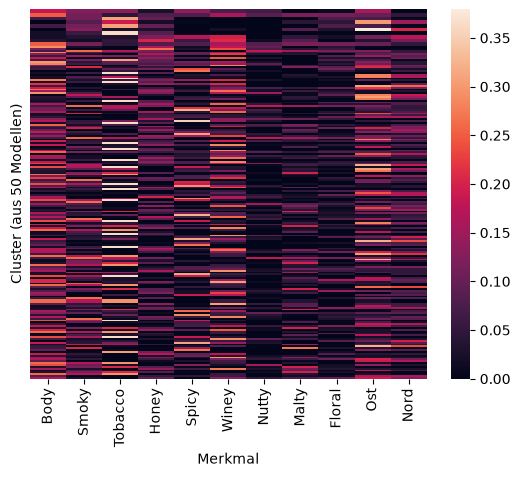

In [48]:
# Heatmap: eine Zeile je Cluster, eine Spalte je Merkmal
ax = sns.heatmap(result.drop(["ncluster", "group"], axis = 1))
ax.set(xlabel = 'Merkmal', ylabel = 'Cluster (aus 50 Modellen)', yticks = [])
plt.show()

Jede Zeile der Heatmap ist ein Cluster aus einem der 50 Modelle, jede Spalte ein Merkmal. Helle Felder bedeuten eine hohe Mutual Information. Die hellen Streifen bei `Tobacco` und `Ost` zeigen, dass diese Merkmale in vielen Modellen die Zugehörigkeit zu einem Cluster stark bestimmen, während `Nutty` und `Floral` fast durchgehend dunkel bleiben. Solche Merkmale könnte man für die Clusteranalyse weglassen, ohne viel Information zu verlieren.

## Zusammenfassung

* **k-means** teilt die Daten in eine vorgegebene Anzahl von Clustern ein und beschreibt jedes Cluster durch sein Zentrum.
* **Agglomeratives Clustering** (hier mit dem Ward-Verfahren) baut eine Hierarchie von Clustern auf, die sich als Dendrogramm darstellen lässt, und hängt nicht von zufälligen Startwerten ab.
* **DBSCAN** findet dichte Regionen, bestimmt die Anzahl der Cluster selbst und markiert Ausreißer als Rauschen.
* **Evaluation:** Die Hopkins-Statistik prüft, ob die Daten überhaupt Cluster enthalten. Elbow-Methode und Silhouette-Koeffizient helfen bei der Wahl der Anzahl der Cluster. Der Adjusted Rand Index vergleicht zwei Einteilungen miteinander.
* **DENCLUE** schätzt eine glatte Dichtefunktion und ordnet jede Beobachtung dem Dichte-Gipfel (Attraktor) zu, zu dem sie bergauf gelangt.
* **PageRank** misst, wie zentral ein Knoten in einem Netzwerk ist. Im Whisky-Netzwerk sind das die Whiskys mit typischem, ausgewogenem Profil.
* Das **Stochastic Block Model** beschreibt Netzwerke, in denen die Kantenwahrscheinlichkeit nur von den Blöcken der Knoten abhängt. Mit Spectral Clustering lassen sich die Blöcke schätzen.
* Im Whisky-Datensatz zeigt sich ein deutliches Cluster aus rauchigen Whiskys bzw. Whiskys mit Tabaknote. Die Clusterstruktur beim Geschmack ist insgesamt aber schwach, die Standorte der Destillerien sind deutlich stärker geclustert.

## Quellen

* Han, J., Pei, J. und Tong, H. (2023): Data Mining: Concepts and Techniques. 4. Auflage. Morgan Kaufmann.
* Kelleher, J. D., Mac Namee, B. und D'Arcy, A. (2020): Fundamentals of Machine Learning for Predictive Data Analytics: Algorithms, Worked Examples, and Case Studies. 2. Auflage. MIT Press.
* https://www.kaggle.com/datasets/koki25ando/scotch-whisky-dataset
* https://simplemaps.com/gis/country/gb
* https://geopandas.org/
* https://scikit-learn.org/stable/modules/clustering.html
* https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html
* https://www.w3schools.com/python/python_ml_k-means.asp
* https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.link_analysis.pagerank_alg.pagerank.html
* https://networkx.org/documentation/stable/reference/generated/networkx.generators.community.stochastic_block_model.html
* https://scikit-learn.org/stable/modules/clustering.html#spectral-clustering
* https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.dendrogram.html
* Hinneburg, A. und Keim, D. A. (1998): An Efficient Approach to Clustering in Large Multimedia Databases with Noise. KDD-98.